In [1]:
import torch
from torchvision.datasets import ImageFolder
from torchvision import transforms
from torch.utils.data import random_split,DataLoader
import matplotlib.pyplot as plt
import torch.nn as nn 
import torch.optim as optim

In [2]:
transform = transforms.Compose([
                                  transforms.RandomHorizontalFlip(),
                                  transforms.RandomRotation(15),
                                  transforms.ColorJitter(brightness=0.2,contrast=0.2, saturation=0.2),
                                  transforms.Resize((224, 224)),
                                  transforms.ToTensor(),
                                  transforms.Normalize(mean=[0.5,0.5,0.5],std=[0.5,0.5,0.5])
                                ])
dataset = ImageFolder(root="FRUIT-16K", transform=transform)

In [3]:
dataset

Dataset ImageFolder
    Number of datapoints: 16000
    Root location: FRUIT-16K
    StandardTransform
Transform: Compose(
               RandomHorizontalFlip(p=0.5)
               RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
               ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=(0.8, 1.2), hue=None)
               Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
               ToTensor()
               Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
           )

In [4]:
classes=dataset.classes
classes

['F_Banana',
 'F_Lemon',
 'F_Lulo',
 'F_Mango',
 'F_Orange',
 'F_Strawberry',
 'F_Tamarillo',
 'F_Tomato',
 'S_Banana',
 'S_Lemon',
 'S_Lulo',
 'S_Mango',
 'S_Orange',
 'S_Strawberry',
 'S_Tamarillo',
 'S_Tomato']

In [5]:
num_classes=len(classes)
num_classes

16

In [6]:
train_size=int(0.75*len(dataset))
val_size=len(dataset)-train_size

train_size,val_size

(12000, 4000)

In [7]:
train_dataset,val_dataset=random_split(dataset,[train_size,val_size])

In [8]:

train_loader=DataLoader(train_dataset,batch_size=32,shuffle=True)
val_loader=DataLoader(val_dataset,batch_size=32,shuffle=True)

In [9]:
for images,labels in train_loader:
    print(images.shape)
    print(labels.shape)
    break

torch.Size([32, 3, 224, 224])
torch.Size([32])


In [10]:
images[0].shape

torch.Size([3, 224, 224])

In [11]:
images[0].permute(1,2,0).shape

torch.Size([224, 224, 3])

In [12]:
classes[labels[10]]

'F_Banana'

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..0.41176474].


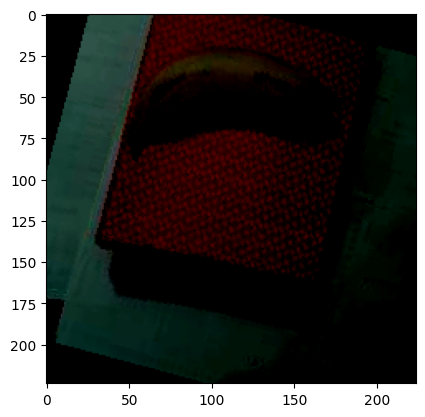

In [13]:
plt.imshow(images[10].permute(1,2,0))
plt.show()

# Model Training

In [14]:
class Freshness_inspection_1(nn.Module):
  def __init__(self):
    super().__init__()
    self.network = nn.Sequential(
                                    nn.Conv2d(3,32,kernel_size=(3,3),padding='same'),  # output (32,224,224)
                                    nn.ReLU(),
                                    nn.MaxPool2d(kernel_size=(2,2),stride=(2,2)),   # output (32,112,112)
                                    nn.Conv2d(32,64,kernel_size=(3,3)),  # output (64,110,110)
                                    nn.ReLU(),
                                    nn.MaxPool2d(kernel_size=(2,2),stride=(2,2)),   # output (64,55,55)
                                    
                                    nn.Flatten(),
                                    nn.Linear(64*55*55, 1000),
                                    nn.ReLU(),
                                    nn.Linear(1000,16)
                                )
  def forward(self,x):
    return self.network(x)

In [15]:
device = torch.device(torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else 'cpu')

# Assuming that we are on a CUDA machine, this should print a CUDA device:

print(device)

cuda


In [16]:
 
import time
import torch
import matplotlib.pyplot as plt

def train_model(model, criterion, optimizer, epochs=5):

    start = time.time()

    # Store accuracy for each epoch
    train_accuracies = []
    val_accuracies = []

    for epoch in range(epochs):

        # ---------------- Training ----------------
        model.train()
        running_loss = 0.0
        train_correct = 0
        train_total = 0

        for batch_num, (images, labels) in enumerate(train_loader):

            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()

            # Forward pass
            outputs = model(images)
            loss = criterion(outputs, labels)

            # Backward pass
            loss.backward()
            optimizer.step()

            # Training accuracy
            _, predicted = torch.max(outputs.data, 1)
            train_total += labels.size(0)
            train_correct += (predicted == labels).sum().item()

            if (batch_num + 1) % 10 == 0:
                print(f"Batch: {batch_num+1}, Epoch: {epoch+1}, Loss: {loss.item():0.2f}")

            running_loss += loss.item() * images.size(0)

        epoch_loss = running_loss / len(train_loader.dataset)

        train_accuracy = 100 * train_correct / train_total
        train_accuracies.append(train_accuracy)

        print(f"Epoch [{epoch+1}/{epochs}], Avg Loss: {epoch_loss:.4f}")
        print(f"*** Training Accuracy: {train_accuracy:.2f}% ***")

        # ---------------- Validation ----------------
        model.eval()
        correct = 0
        total = 0

        all_labels = []
        all_predictions = []

        with torch.no_grad():

            for images, labels in val_loader:

                images, labels = images.to(device), labels.to(device)

                outputs = model(images)
                _, predicted = torch.max(outputs.data, 1)

                total += labels.size(0)
                correct += (predicted == labels).sum().item()

                all_labels.extend(labels.cpu().numpy())
                all_predictions.extend(predicted.cpu().numpy())

        val_accuracy = 100 * correct / total
        val_accuracies.append(val_accuracy)

        print(f"*** Validation Accuracy: {val_accuracy:.2f}% ***")

    end = time.time()

    print(f"Execution time: {end - start:.2f} seconds")

    # ---------------- Plot Accuracy ----------------
    plt.figure(figsize=(8, 5))

    plt.plot(range(1, epochs+1), train_accuracies,
             marker='o', label='Training Accuracy')

    plt.plot(range(1, epochs+1), val_accuracies,
             marker='o', label='Validation Accuracy')

    plt.title("Training vs Validation Accuracy")
    plt.xlabel("Epochs")
    plt.ylabel("Accuracy (%)")
    plt.xticks(range(1, epochs+1))
    plt.legend()
    plt.grid(True)
    plt.show()

    return all_labels, all_predictions


Batch: 10, Epoch: 1, Loss: 2.73
Batch: 20, Epoch: 1, Loss: 2.78
Batch: 30, Epoch: 1, Loss: 2.64
Batch: 40, Epoch: 1, Loss: 2.55
Batch: 50, Epoch: 1, Loss: 2.69
Batch: 60, Epoch: 1, Loss: 2.49
Batch: 70, Epoch: 1, Loss: 2.58
Batch: 80, Epoch: 1, Loss: 2.33
Batch: 90, Epoch: 1, Loss: 2.42
Batch: 100, Epoch: 1, Loss: 2.38
Batch: 110, Epoch: 1, Loss: 2.45
Batch: 120, Epoch: 1, Loss: 2.57
Batch: 130, Epoch: 1, Loss: 2.44
Batch: 140, Epoch: 1, Loss: 2.24
Batch: 150, Epoch: 1, Loss: 2.06
Batch: 160, Epoch: 1, Loss: 2.25
Batch: 170, Epoch: 1, Loss: 1.82
Batch: 180, Epoch: 1, Loss: 2.26
Batch: 190, Epoch: 1, Loss: 2.11
Batch: 200, Epoch: 1, Loss: 2.14
Batch: 210, Epoch: 1, Loss: 1.95
Batch: 220, Epoch: 1, Loss: 2.30
Batch: 230, Epoch: 1, Loss: 1.89
Batch: 240, Epoch: 1, Loss: 2.24
Batch: 250, Epoch: 1, Loss: 2.12
Batch: 260, Epoch: 1, Loss: 1.83
Batch: 270, Epoch: 1, Loss: 2.13
Batch: 280, Epoch: 1, Loss: 2.05
Batch: 290, Epoch: 1, Loss: 1.89
Batch: 300, Epoch: 1, Loss: 2.57
Batch: 310, Epoch: 

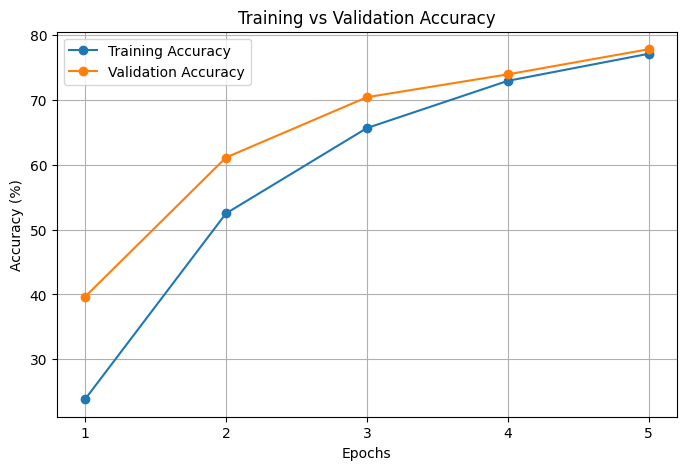

In [18]:
model = Freshness_inspection_1().to(device)
epochs = 10
learning_rate = 0.001
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(),lr=learning_rate)
all_labels, all_predictions = train_model(model, loss_fn, optimizer)

# Batch Normalization

In [19]:
class Freshness_CNN_BN(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(

            nn.Conv2d(3, 32, kernel_size=3, padding='same'),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(32, 64, kernel_size=3),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.AdaptiveAvgPool2d((1, 1)),

            nn.Flatten(),

            nn.Linear(64, 128),
            nn.ReLU(),

            nn.Linear(128, 16)
        )

    def forward(self, x):
        return self.network(x)

Batch: 10, Epoch: 1, Loss: 2.72
Batch: 20, Epoch: 1, Loss: 2.68
Batch: 30, Epoch: 1, Loss: 2.65
Batch: 40, Epoch: 1, Loss: 2.63
Batch: 50, Epoch: 1, Loss: 2.54
Batch: 60, Epoch: 1, Loss: 2.43
Batch: 70, Epoch: 1, Loss: 2.35
Batch: 80, Epoch: 1, Loss: 2.17
Batch: 90, Epoch: 1, Loss: 2.34
Batch: 100, Epoch: 1, Loss: 2.21
Batch: 110, Epoch: 1, Loss: 2.14
Batch: 120, Epoch: 1, Loss: 2.08
Batch: 130, Epoch: 1, Loss: 1.96
Batch: 140, Epoch: 1, Loss: 2.00
Batch: 150, Epoch: 1, Loss: 2.22
Batch: 160, Epoch: 1, Loss: 1.80
Batch: 170, Epoch: 1, Loss: 1.81
Batch: 180, Epoch: 1, Loss: 2.03
Batch: 190, Epoch: 1, Loss: 1.98
Batch: 200, Epoch: 1, Loss: 1.90
Batch: 210, Epoch: 1, Loss: 1.78
Batch: 220, Epoch: 1, Loss: 1.69
Batch: 230, Epoch: 1, Loss: 1.97
Batch: 240, Epoch: 1, Loss: 1.96
Batch: 250, Epoch: 1, Loss: 1.88
Batch: 260, Epoch: 1, Loss: 1.69
Batch: 270, Epoch: 1, Loss: 1.86
Batch: 280, Epoch: 1, Loss: 1.82
Batch: 290, Epoch: 1, Loss: 1.77
Batch: 300, Epoch: 1, Loss: 1.59
Batch: 310, Epoch: 

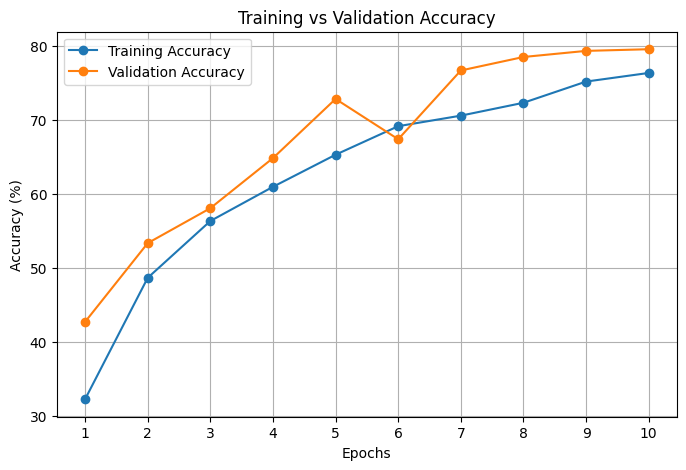

In [20]:
model = Freshness_CNN_BN().to(device)

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

all_labels, all_predictions = train_model(
    model, loss_fn, optimizer, epochs=10
)

# Batch Normalization + Dropout

In [21]:
class Freshness_CNN_BN_Dropout(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(

            # Block 1
            nn.Conv2d(3, 32, kernel_size=3, padding='same'),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.1),

            # Block 2
            nn.Conv2d(32, 64, kernel_size=3),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.1),

            nn.AdaptiveAvgPool2d((1, 1)),

            nn.Flatten(),

            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Dropout(0.5),

            nn.Linear(128, 16)
        )

    def forward(self, x):
        return self.network(x)

Batch: 10, Epoch: 1, Loss: 2.75
Batch: 20, Epoch: 1, Loss: 2.74
Batch: 30, Epoch: 1, Loss: 2.71
Batch: 40, Epoch: 1, Loss: 2.72
Batch: 50, Epoch: 1, Loss: 2.69
Batch: 60, Epoch: 1, Loss: 2.64
Batch: 70, Epoch: 1, Loss: 2.63
Batch: 80, Epoch: 1, Loss: 2.59
Batch: 90, Epoch: 1, Loss: 2.56
Batch: 100, Epoch: 1, Loss: 2.70
Batch: 110, Epoch: 1, Loss: 2.44
Batch: 120, Epoch: 1, Loss: 2.47
Batch: 130, Epoch: 1, Loss: 2.43
Batch: 140, Epoch: 1, Loss: 2.36
Batch: 150, Epoch: 1, Loss: 2.32
Batch: 160, Epoch: 1, Loss: 2.52
Batch: 170, Epoch: 1, Loss: 2.33
Batch: 180, Epoch: 1, Loss: 2.37
Batch: 190, Epoch: 1, Loss: 2.30
Batch: 200, Epoch: 1, Loss: 2.22
Batch: 210, Epoch: 1, Loss: 2.31
Batch: 220, Epoch: 1, Loss: 2.32
Batch: 230, Epoch: 1, Loss: 2.06
Batch: 240, Epoch: 1, Loss: 2.28
Batch: 250, Epoch: 1, Loss: 2.13
Batch: 260, Epoch: 1, Loss: 2.06
Batch: 270, Epoch: 1, Loss: 2.34
Batch: 280, Epoch: 1, Loss: 2.10
Batch: 290, Epoch: 1, Loss: 2.19
Batch: 300, Epoch: 1, Loss: 2.14
Batch: 310, Epoch: 

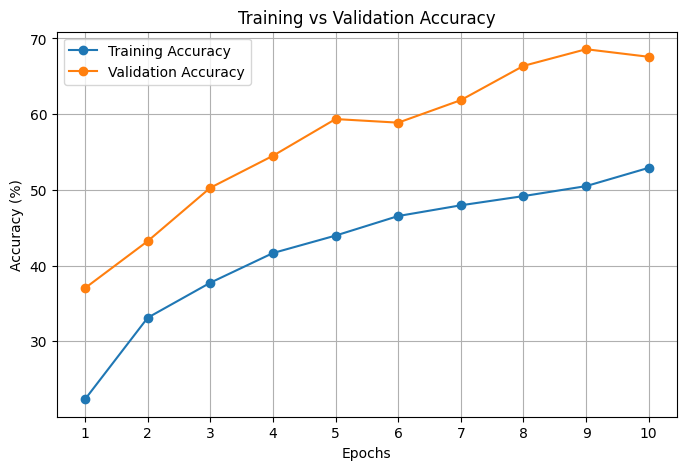

In [22]:
model = Freshness_CNN_BN_Dropout().to(device)

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

all_labels, all_predictions = train_model(
    model, loss_fn, optimizer, epochs=10
)

# Batch Normalization + Dropout + Weight Decay

Batch: 10, Epoch: 1, Loss: 2.80
Batch: 20, Epoch: 1, Loss: 2.78
Batch: 30, Epoch: 1, Loss: 2.76
Batch: 40, Epoch: 1, Loss: 2.75
Batch: 50, Epoch: 1, Loss: 2.69
Batch: 60, Epoch: 1, Loss: 2.62
Batch: 70, Epoch: 1, Loss: 2.71
Batch: 80, Epoch: 1, Loss: 2.58
Batch: 90, Epoch: 1, Loss: 2.66
Batch: 100, Epoch: 1, Loss: 2.49
Batch: 110, Epoch: 1, Loss: 2.54
Batch: 120, Epoch: 1, Loss: 2.49
Batch: 130, Epoch: 1, Loss: 2.42
Batch: 140, Epoch: 1, Loss: 2.61
Batch: 150, Epoch: 1, Loss: 2.39
Batch: 160, Epoch: 1, Loss: 2.26
Batch: 170, Epoch: 1, Loss: 2.46
Batch: 180, Epoch: 1, Loss: 2.30
Batch: 190, Epoch: 1, Loss: 2.11
Batch: 200, Epoch: 1, Loss: 2.38
Batch: 210, Epoch: 1, Loss: 2.30
Batch: 220, Epoch: 1, Loss: 2.50
Batch: 230, Epoch: 1, Loss: 2.14
Batch: 240, Epoch: 1, Loss: 2.40
Batch: 250, Epoch: 1, Loss: 2.35
Batch: 260, Epoch: 1, Loss: 2.27
Batch: 270, Epoch: 1, Loss: 2.31
Batch: 280, Epoch: 1, Loss: 2.28
Batch: 290, Epoch: 1, Loss: 2.26
Batch: 300, Epoch: 1, Loss: 2.29
Batch: 310, Epoch: 

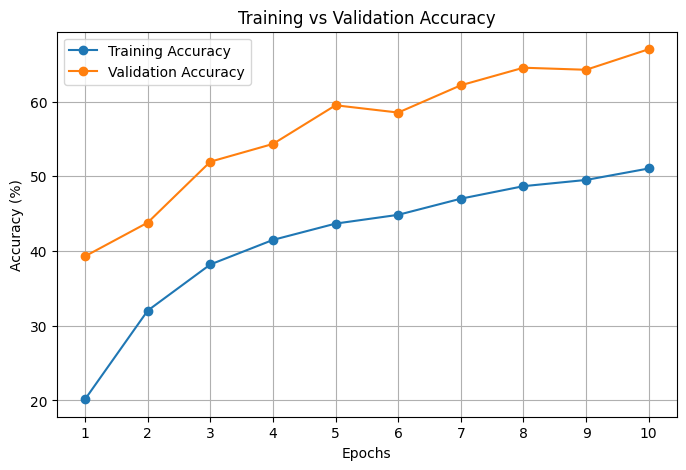

In [23]:
model = Freshness_CNN_BN_Dropout().to(device)

optimizer = optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

all_labels, all_predictions = train_model(
    model, loss_fn, optimizer, epochs=10
)

# All techniques + Early Stopping

In [24]:
model = Freshness_CNN_BN_Dropout().to(device)

optimizer = optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

In [27]:
import copy
def train_model_early_stopping(
    model,
    criterion,
    optimizer,
    epochs=30,
    patience=5
):

    start = time.time()

    train_losses = []
    val_losses = []

    train_accuracies = []
    val_accuracies = []

    best_val_loss = float('inf')
    best_model_weights = copy.deepcopy(model.state_dict())

    patience_counter = 0

    best_labels = []
    best_predictions = []

    for epoch in range(epochs):

        # -------- Training --------
        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        train_loss = running_loss / total
        train_accuracy = 100 * correct / total

        train_losses.append(train_loss)
        train_accuracies.append(train_accuracy)

        # -------- Validation --------
        model.eval()

        val_running_loss = 0.0
        correct = 0
        total = 0

        all_labels = []
        all_predictions = []

        with torch.no_grad():

            for images, labels in val_loader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)

                loss = criterion(outputs, labels)

                val_running_loss += loss.item() * images.size(0)

                _, predicted = torch.max(outputs, 1)

                total += labels.size(0)
                correct += (predicted == labels).sum().item()

                all_labels.extend(labels.cpu().numpy())
                all_predictions.extend(predicted.cpu().numpy())

        val_loss = val_running_loss / total
        val_accuracy = 100 * correct / total

        val_losses.append(val_loss)
        val_accuracies.append(val_accuracy)

        print(f"\nEpoch [{epoch+1}/{epochs}]")
        print(f"Train Loss: {train_loss:.4f}")
        print(f"Train Accuracy: {train_accuracy:.2f}%")
        print(f"Validation Loss: {val_loss:.4f}")
        print(f"Validation Accuracy: {val_accuracy:.2f}%")

        # -------- Early Stopping --------
        if val_loss < best_val_loss:

            best_val_loss = val_loss

            best_model_weights = copy.deepcopy(
                model.state_dict()
            )

            best_labels = all_labels.copy()
            best_predictions = all_predictions.copy()

            patience_counter = 0

            print("Best model saved!")

        else:

            patience_counter += 1

            print(
                f"No improvement: "
                f"{patience_counter}/{patience}"
            )

            if patience_counter >= patience:

                print("Early stopping triggered!")
                break

    # Restore best weights
    model.load_state_dict(best_model_weights)

    # -------- Plot Accuracy --------
    epochs_range = range(1, len(train_accuracies) + 1)

    plt.figure(figsize=(8, 5))

    plt.plot(
        epochs_range,
        train_accuracies,
        marker='o',
        label='Training Accuracy'
    )

    plt.plot(
        epochs_range,
        val_accuracies,
        marker='o',
        label='Validation Accuracy'
    )

    plt.xlabel("Epochs")
    plt.ylabel("Accuracy (%)")
    plt.title("Training vs Validation Accuracy")
    plt.legend()
    plt.grid(True)
    plt.show()

    # -------- Plot Loss --------
    plt.figure(figsize=(8, 5))

    plt.plot(
        epochs_range,
        train_losses,
        marker='o',
        label='Training Loss'
    )

    plt.plot(
        epochs_range,
        val_losses,
        marker='o',
        label='Validation Loss'
    )

    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.title("Training vs Validation Loss")
    plt.legend()
    plt.grid(True)
    plt.show()

    print(f"\nBest Validation Loss: {best_val_loss:.4f}")
    print(f"Execution Time: {time.time() - start:.2f} seconds")

    return best_labels, best_predictions



Epoch [1/30]
Train Loss: 2.3874
Train Accuracy: 21.14%
Validation Loss: 1.9428
Validation Accuracy: 38.23%
Best model saved!

Epoch [2/30]
Train Loss: 1.9959
Train Accuracy: 32.52%
Validation Loss: 1.6849
Validation Accuracy: 45.42%
Best model saved!

Epoch [3/30]
Train Loss: 1.8034
Train Accuracy: 37.33%
Validation Loss: 1.4532
Validation Accuracy: 51.10%
Best model saved!

Epoch [4/30]
Train Loss: 1.7001
Train Accuracy: 41.39%
Validation Loss: 1.3483
Validation Accuracy: 54.38%
Best model saved!

Epoch [5/30]
Train Loss: 1.5986
Train Accuracy: 43.52%
Validation Loss: 1.2795
Validation Accuracy: 56.45%
Best model saved!

Epoch [6/30]
Train Loss: 1.5317
Train Accuracy: 45.85%
Validation Loss: 1.1988
Validation Accuracy: 60.83%
Best model saved!

Epoch [7/30]
Train Loss: 1.4964
Train Accuracy: 46.97%
Validation Loss: 1.1498
Validation Accuracy: 62.75%
Best model saved!

Epoch [8/30]
Train Loss: 1.4524
Train Accuracy: 48.04%
Validation Loss: 1.1184
Validation Accuracy: 63.70%
Best model

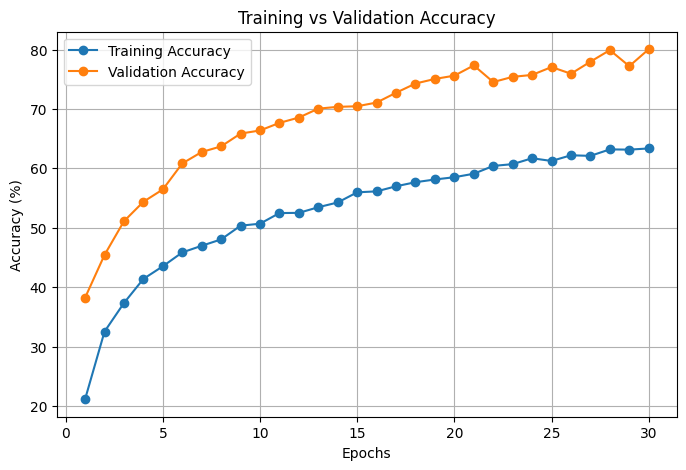

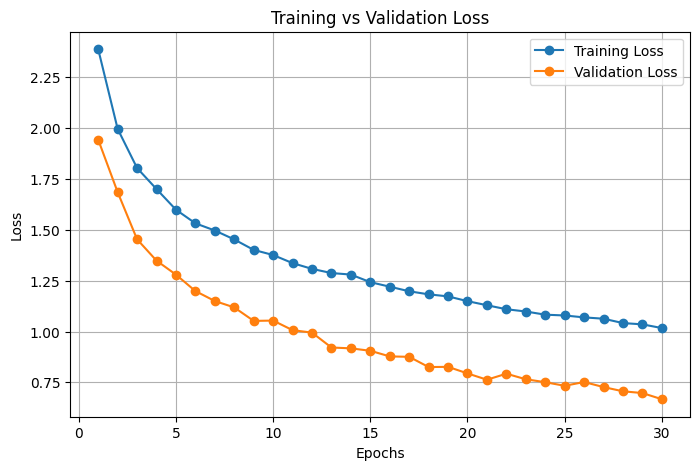


Best Validation Loss: 0.6672
Execution Time: 4083.93 seconds


In [28]:
model = Freshness_CNN_BN_Dropout().to(device)

optimizer = optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

all_labels, all_predictions = train_model_early_stopping(
    model,
    loss_fn,
    optimizer,
    epochs=30,
    patience=5
)

In [37]:
import os
import torch

os.makedirs("models", exist_ok=True)

model_path = "models/freshharvest_cnn.pth"

torch.save(model.state_dict(), model_path)

print("Model saved successfully:", model_path)

Model saved successfully: models/freshharvest_cnn.pth


In [38]:
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import copy
import time

from sklearn.metrics import accuracy_score
from torch.utils.data import DataLoader

In [42]:
def run_tuning(lr, batch_size, optimizer_name, weight_decay):

    # Reload original saved weights for a fair comparison
    model = Freshness_CNN_BN_Dropout().to(device)

    model.load_state_dict(
        torch.load(
            "models\\freshharvest_cnn.pth",
            map_location=device,
            weights_only=True
        )
    )

    train_dl = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0,
        pin_memory=True
    )

    val_dl = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
        pin_memory=True
    )

    if optimizer_name == "Adam":
        optimizer = optim.Adam(
            model.parameters(),
            lr=lr,
            weight_decay=weight_decay
        )

    elif optimizer_name == "AdamW":
        optimizer = optim.AdamW(
            model.parameters(),
            lr=lr,
            weight_decay=weight_decay
        )

    else:
        optimizer = optim.SGD(
            model.parameters(),
            lr=lr,
            momentum=0.9,
            weight_decay=weight_decay
        )

    start = time.time()

    # Use your existing function, modified to accept train_dl and val_dl
    best_val_accuracy, best_val_loss = fine_tune_model(
        model=model,
        train_loader=train_dl,
        val_loader=val_dl,
        optimizer=optimizer,
        criterion=loss_fn,
        epochs=10,
        patience=3
    )

    return {
        "Learning Rate": lr,
        "Batch Size": batch_size,
        "Optimizer": optimizer_name,
        "Weight Decay": weight_decay,
        "Validation Accuracy": best_val_accuracy,
        "Validation Loss": best_val_loss,
        "Time (min)": (time.time() - start) / 60
    }

In [45]:
import copy
import torch

def fine_tune_model(
    model,
    train_loader,
    val_loader,
    optimizer,
    criterion,
    epochs=10,
    patience=3
):
    best_val_loss = float("inf")
    best_val_accuracy = 0.0
    best_weights = copy.deepcopy(model.state_dict())
    patience_counter = 0

    for epoch in range(epochs):

        # Training
        model.train()
        train_correct = 0
        train_total = 0
        train_loss = 0.0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            train_loss += loss.item()
            predictions = outputs.argmax(dim=1)

            train_correct += (predictions == labels).sum().item()
            train_total += labels.size(0)

        train_accuracy = 100 * train_correct / train_total

        # Validation
        model.eval()
        val_correct = 0
        val_total = 0
        val_loss = 0.0

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss += loss.item()

                predictions = outputs.argmax(dim=1)
                val_correct += (predictions == labels).sum().item()
                val_total += labels.size(0)

        val_accuracy = 100 * val_correct / val_total
        avg_val_loss = val_loss / len(val_loader)

        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Train Acc: {train_accuracy:.2f}% | "
            f"Val Acc: {val_accuracy:.2f}% | "
            f"Val Loss: {avg_val_loss:.4f}"
        )

        # Early stopping
        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            best_val_accuracy = val_accuracy
            best_weights = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1

        if patience_counter >= patience:
            print("Early stopping triggered!")
            break

    model.load_state_dict(best_weights)

    return best_val_accuracy, best_val_loss

In [46]:
experiments = [
    (0.001, 8, "Adam", 0.0001),
    (0.0005, 8, "Adam", 0.0001),
    (0.0001, 8, "Adam", 0.0001),

    (0.0005, 16, "Adam", 0.0001),
    (0.0005, 8, "AdamW", 0.0001),
    (0.0005, 8, "SGD", 0.0001),

    (0.0005, 8, "AdamW", 0.001),
]

results = []

for params in experiments:
    result = run_tuning(*params)
    results.append(result)

    # Release GPU resources between experiments
    del result
    torch.cuda.empty_cache()

Epoch [1/10] Train Acc: 55.10% | Val Acc: 74.70% | Val Loss: 0.7804
Epoch [2/10] Train Acc: 57.15% | Val Acc: 75.12% | Val Loss: 0.7778
Epoch [3/10] Train Acc: 57.46% | Val Acc: 75.65% | Val Loss: 0.7975
Epoch [4/10] Train Acc: 58.52% | Val Acc: 77.03% | Val Loss: 0.7234
Epoch [5/10] Train Acc: 58.33% | Val Acc: 78.08% | Val Loss: 0.7511
Epoch [6/10] Train Acc: 59.17% | Val Acc: 78.62% | Val Loss: 0.7443
Epoch [7/10] Train Acc: 59.53% | Val Acc: 78.22% | Val Loss: 0.7336
Early stopping triggered!
Epoch [1/10] Train Acc: 57.70% | Val Acc: 80.08% | Val Loss: 0.6852
Epoch [2/10] Train Acc: 57.17% | Val Acc: 78.92% | Val Loss: 0.7347
Epoch [3/10] Train Acc: 58.25% | Val Acc: 78.25% | Val Loss: 0.7494
Epoch [4/10] Train Acc: 58.92% | Val Acc: 78.25% | Val Loss: 0.7055
Early stopping triggered!
Epoch [1/10] Train Acc: 57.51% | Val Acc: 79.62% | Val Loss: 0.6643
Epoch [2/10] Train Acc: 57.63% | Val Acc: 79.97% | Val Loss: 0.6807
Epoch [3/10] Train Acc: 58.22% | Val Acc: 80.78% | Val Loss: 0.6

In [47]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Validation Accuracy",
    ascending=False
)

display(results_df)

,Learning Rate,Batch Size,Optimizer,Weight Decay,Validation Accuracy,Validation Loss,Time (min)
3,0.0005,16,Adam,0.0001,80.450,0.643310,9.831930
1,0.0005,8,Adam,0.0001,80.075,0.685246,7.257930
6,0.0005,8,AdamW,0.0010,79.900,0.691834,12.772267
2,0.0001,8,Adam,0.0001,79.625,0.664306,7.167970
4,0.0005,8,AdamW,0.0001,79.625,0.701066,7.546362
5,0.0005,8,SGD,0.0001,78.600,0.683581,35.711427
0,0.0010,8,Adam,0.0001,77.025,0.723358,13.773561


In [48]:
def run_tuning(lr, batch_size, optimizer_name, weight_decay):

    # Reload original saved weights for a fair comparison
    model = Freshness_CNN_BN_Dropout().to(device)

    model.load_state_dict(
        torch.load(
            "models\\freshharvest_cnn.pth",
            map_location=device,
            weights_only=True
        )
    )

    train_dl = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0,
        pin_memory=True
    )

    val_dl = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
        pin_memory=True
    )

    if optimizer_name == "Adam":
        optimizer = optim.Adam(
            model.parameters(),
            lr=lr,
            weight_decay=weight_decay
        )

    elif optimizer_name == "AdamW":
        optimizer = optim.AdamW(
            model.parameters(),
            lr=lr,
            weight_decay=weight_decay
        )

    else:
        optimizer = optim.SGD(
            model.parameters(),
            lr=lr,
            momentum=0.9,
            weight_decay=weight_decay
        )

    start = time.time()

    # Use your existing function, modified to accept train_dl and val_dl
    best_val_accuracy, best_val_loss = fine_tune_model(
        model=model,
        train_loader=train_dl,
        val_loader=val_dl,
        optimizer=optimizer,
        criterion=loss_fn,
        epochs=10,
        patience=3
    )

    return {
    "Learning Rate": lr,
    "Batch Size": batch_size,
    "Optimizer": optimizer_name,
    "Weight Decay": weight_decay,
    "Validation Accuracy": best_val_accuracy,
    "Validation Loss": best_val_loss,
    "Time (min)": (time.time() - start) / 60,
    "Model State": copy.deepcopy(model.state_dict())
}

In [49]:
experiments = [
    (0.001, 8, "Adam", 0.0001),
    (0.0005, 8, "Adam", 0.0001),
    (0.0001, 8, "Adam", 0.0001),

    (0.0005, 16, "Adam", 0.0001),
    (0.0005, 8, "AdamW", 0.0001),
    (0.0005, 8, "SGD", 0.0001),

    (0.0005, 8, "AdamW", 0.001),
]

results = []

for params in experiments:
    result = run_tuning(*params)
    results.append(result)

    # Release GPU resources between experiments
    del result
    torch.cuda.empty_cache()

Epoch [1/10] Train Acc: 55.82% | Val Acc: 74.90% | Val Loss: 0.7788
Epoch [2/10] Train Acc: 56.77% | Val Acc: 76.67% | Val Loss: 0.7867
Epoch [3/10] Train Acc: 57.42% | Val Acc: 76.33% | Val Loss: 0.7625
Epoch [4/10] Train Acc: 57.63% | Val Acc: 75.85% | Val Loss: 0.8152
Epoch [5/10] Train Acc: 58.27% | Val Acc: 77.45% | Val Loss: 0.7195
Epoch [6/10] Train Acc: 59.24% | Val Acc: 79.38% | Val Loss: 0.7280
Epoch [7/10] Train Acc: 60.14% | Val Acc: 73.72% | Val Loss: 0.7950
Epoch [8/10] Train Acc: 60.83% | Val Acc: 79.35% | Val Loss: 0.6881
Epoch [9/10] Train Acc: 61.38% | Val Acc: 78.90% | Val Loss: 0.6978
Epoch [10/10] Train Acc: 61.21% | Val Acc: 78.92% | Val Loss: 0.7106
Epoch [1/10] Train Acc: 56.58% | Val Acc: 78.42% | Val Loss: 0.7147
Epoch [2/10] Train Acc: 57.69% | Val Acc: 78.42% | Val Loss: 0.7251
Epoch [3/10] Train Acc: 58.83% | Val Acc: 78.92% | Val Loss: 0.7112
Epoch [4/10] Train Acc: 58.88% | Val Acc: 80.00% | Val Loss: 0.6853
Epoch [5/10] Train Acc: 59.22% | Val Acc: 77.62

In [50]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Validation Accuracy",
    ascending=False
)

display(results_df)

,Learning Rate,Batch Size,Optimizer,Weight Decay,Validation Accuracy,Validation Loss,Time (min),Model State
2,0.0001,8,Adam,0.0001,81.650,0.657168,11.029095,"{'network.0.weight': [[tensor([[-0.1697, -0.04..."
3,0.0005,16,Adam,0.0001,80.950,0.657368,6.833810,"{'network.0.weight': [[tensor([[-0.1646, -0.03..."
1,0.0005,8,Adam,0.0001,80.150,0.666949,19.099549,"{'network.0.weight': [[tensor([[-1.9588e-01, -..."
0,0.0010,8,Adam,0.0001,79.350,0.688113,19.197251,"{'network.0.weight': [[tensor([[-0.2016, -0.09..."
5,0.0005,8,SGD,0.0001,78.925,0.695406,44.093021,"{'network.0.weight': [[tensor([[-0.1768, -0.04..."
4,0.0005,8,AdamW,0.0001,78.575,0.698301,7.466021,"{'network.0.weight': [[tensor([[-0.1657, -0.03..."
6,0.0005,8,AdamW,0.0010,78.025,0.710610,32.640255,"{'network.0.weight': [[tensor([[-0.1682, -0.04..."


In [51]:
import os
import torch

# Find best-performing experiment
best_result = max(
    results,
    key=lambda x: x["Validation Accuracy"]
)

# Create models directory
os.makedirs("models", exist_ok=True)

# Save model and experiment details
checkpoint = {
    "model_state_dict": best_result["Model State"],
    "learning_rate": best_result["Learning Rate"],
    "batch_size": best_result["Batch Size"],
    "optimizer": best_result["Optimizer"],
    "weight_decay": best_result["Weight Decay"],
    "validation_accuracy": best_result["Validation Accuracy"],
    "validation_loss": best_result["Validation Loss"]
}

torch.save(
    checkpoint,
    "models/freshharvest_best_model.pth"
)

print("Best model saved successfully!")
print("Best validation accuracy:", best_result["Validation Accuracy"])
print("Best hyperparameters:", {
    k: best_result[k]
    for k in [
        "Learning Rate",
        "Batch Size",
        "Optimizer",
        "Weight Decay"
    ]
})

Best model saved successfully!
Best validation accuracy: 81.65
Best hyperparameters: {'Learning Rate': 0.0001, 'Batch Size': 8, 'Optimizer': 'Adam', 'Weight Decay': 0.0001}


# Transfer Learning

In [52]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.models as models
import torchvision.transforms as transforms

import copy
import os
import time
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from torchvision.models import ResNet50_Weights

In [53]:
device

device(type='cuda')

In [55]:
from torchvision import transforms

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [56]:
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader, random_split, Subset
import torch

dataset = ImageFolder(root="FRUIT-16K")

train_size = int(0.75 * len(dataset))
val_size = len(dataset) - train_size

generator = torch.Generator().manual_seed(42)

train_subset, val_subset = random_split(
    dataset,
    [train_size, val_size],
    generator=generator
)

train_dataset = Subset(
    ImageFolder(root="FRUIT-16K", transform=train_transform),
    train_subset.indices
)

val_dataset = Subset(
    ImageFolder(root="FRUIT-16K", transform=val_transform),
    val_subset.indices
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Classes:", dataset.classes)
print("Number of classes:", len(dataset.classes))

Training images: 12000
Validation images: 4000
Classes: ['F_Banana', 'F_Lemon', 'F_Lulo', 'F_Mango', 'F_Orange', 'F_Strawberry', 'F_Tamarillo', 'F_Tomato', 'S_Banana', 'S_Lemon', 'S_Lulo', 'S_Mango', 'S_Orange', 'S_Strawberry', 'S_Tamarillo', 'S_Tomato']
Number of classes: 16


In [57]:
train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

In [58]:
images, labels = next(iter(train_loader))

print("Image shape:", images.shape)
print("Labels shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Classes:", len(dataset.classes))

Image shape: torch.Size([8, 3, 224, 224])
Labels shape: torch.Size([8])
Image dtype: torch.float32
Classes: 16


In [59]:
weights = ResNet50_Weights.DEFAULT

resnet_model = models.resnet50(weights=weights)

# Freeze pretrained feature extraction layers
for param in resnet_model.parameters():
    param.requires_grad = False

# Replace final classification layer
num_features = resnet_model.fc.in_features

resnet_model.fc = nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(num_features, 16)
)

resnet_model = resnet_model.to(device)

print(resnet_model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [62]:
loss_fn = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    resnet_model.fc.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

In [63]:
def train_resnet(
    model,
    train_loader,
    val_loader,
    optimizer,
    criterion,
    epochs=15,
    patience=5
):
    best_val_loss = float("inf")
    best_weights = copy.deepcopy(model.state_dict())

    patience_counter = 0

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=(device.type == "cuda")
    )

    train_accuracies = []
    val_accuracies = []

    for epoch in range(epochs):

        # Training
        model.train()

        train_correct = 0
        train_total = 0
        train_loss = 0

        for images, labels in train_loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=(device.type == "cuda")
            ):
                outputs = model(images)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            train_loss += loss.item()

            predictions = outputs.argmax(dim=1)

            train_correct += (
                predictions == labels
            ).sum().item()

            train_total += labels.size(0)

        train_accuracy = 100 * train_correct / train_total

        # Validation
        model.eval()

        val_correct = 0
        val_total = 0
        val_loss = 0

        with torch.no_grad():

            for images, labels in val_loader:

                images = images.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)

                with torch.autocast(
                    device_type=device.type,
                    dtype=torch.float16,
                    enabled=(device.type == "cuda")
                ):
                    outputs = model(images)
                    loss = criterion(outputs, labels)

                val_loss += loss.item()

                predictions = outputs.argmax(dim=1)

                val_correct += (
                    predictions == labels
                ).sum().item()

                val_total += labels.size(0)

        val_accuracy = 100 * val_correct / val_total
        avg_val_loss = val_loss / len(val_loader)

        train_accuracies.append(train_accuracy)
        val_accuracies.append(val_accuracy)

        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Train Acc: {train_accuracy:.2f}% | "
            f"Val Acc: {val_accuracy:.2f}% | "
            f"Val Loss: {avg_val_loss:.4f}"
        )

        # Save best model weights
        if avg_val_loss < best_val_loss:

            best_val_loss = avg_val_loss
            best_weights = copy.deepcopy(model.state_dict())

            patience_counter = 0

        else:
            patience_counter += 1

        if patience_counter >= patience:
            print("Early stopping triggered!")
            break

    model.load_state_dict(best_weights)

    return train_accuracies, val_accuracies, best_val_loss

In [66]:
start_time = time.time()

train_acc, val_acc, best_loss = train_resnet(
    model=resnet_model,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer,
    criterion=loss_fn,
    epochs=5,
    patience=5
)

print(f"\nTraining completed in {(time.time()-start_time)/60:.2f} minutes")

Epoch [1/5] Train Acc: 93.86% | Val Acc: 98.67% | Val Loss: 0.1160
Epoch [2/5] Train Acc: 95.75% | Val Acc: 98.70% | Val Loss: 0.0748
Epoch [3/5] Train Acc: 96.48% | Val Acc: 99.22% | Val Loss: 0.0457
Epoch [4/5] Train Acc: 96.79% | Val Acc: 99.33% | Val Loss: 0.0388
Epoch [5/5] Train Acc: 97.04% | Val Acc: 99.25% | Val Loss: 0.0345

Training completed in 9.20 minutes


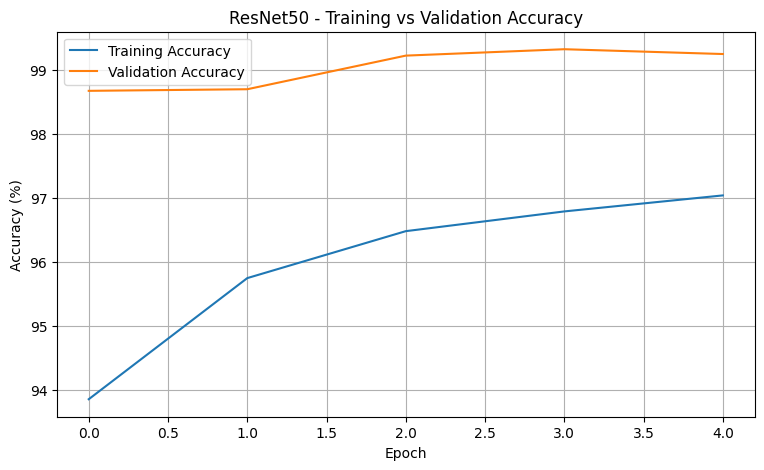

In [67]:
plt.figure(figsize=(9, 5))

plt.plot(train_acc, label="Training Accuracy")
plt.plot(val_acc, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("ResNet50 - Training vs Validation Accuracy")

plt.legend()
plt.grid(True)
plt.show()

In [69]:
for param in resnet_model.layer4.parameters():
    param.requires_grad = True

optimizer = optim.AdamW(
    [
        {"params": resnet_model.layer4.parameters(), "lr": 0.00001},
        {"params": resnet_model.fc.parameters(), "lr": 0.0001}
    ],
    weight_decay=0.0001
)

train_acc_2, val_acc_2, best_loss_2 = train_resnet(
    resnet_model,
    train_loader,
    val_loader,
    optimizer,
    loss_fn,
    epochs=3,
    patience=3
)

Epoch [1/3] Train Acc: 99.66% | Val Acc: 99.97% | Val Loss: 0.0015
Epoch [2/3] Train Acc: 99.73% | Val Acc: 99.95% | Val Loss: 0.0018
Epoch [3/3] Train Acc: 99.83% | Val Acc: 99.92% | Val Loss: 0.0017


In [71]:
os.makedirs("models", exist_ok=True)

checkpoint = {
    "model_name": "ResNet50",
    "model_state_dict": resnet_model.state_dict(),
    "num_classes": 16,
    "class_names": train_dataset.dataset.classes,
    "validation_accuracy": max(val_acc_2 if 'val_acc_2' in globals() else val_acc),
    "validation_loss": best_loss_2 if 'best_loss_2' in globals() else best_loss,
    "input_size": 224
}

torch.save(
    checkpoint,
    "models/freshharvest_resnet50.pth"
)

print("ResNet50 model saved successfully!")

ResNet50 model saved successfully!


In [72]:
checkpoint = torch.load(
    "models/freshharvest_resnet50.pth",
    map_location=device,
    weights_only=True
)

loaded_model = models.resnet50(weights=None)

loaded_model.fc = nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(loaded_model.fc.in_features, 16)
)

loaded_model.load_state_dict(
    checkpoint["model_state_dict"]
)

loaded_model = loaded_model.to(device)
loaded_model.eval()

print("FreshHarvest ResNet50 loaded successfully!")

FreshHarvest ResNet50 loaded successfully!
